In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter
from multifractal_networks.utils.motifs import MotifGenerator

# Load Network

In [5]:
filename = './test_networks/celegans_neural_undirected.csv'
G = nx.read_edgelist(filename, delimiter = ',')

In [6]:
len(G)

543

In [7]:
2 * G.number_of_edges() / G.number_of_nodes()

7.911602209944752

In [8]:
for m_size in [2,3,5,6,7,10,11]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size))+1)

2  k_max:  10
3  k_max:  6
5  k_max:  4
6  k_max:  4
7  k_max:  4
10  k_max:  3
11  k_max:  3


# Init Fitter

In [8]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 200,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.078859
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:01.681407


In [9]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 2148},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 34419},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 0},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 400490},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 0},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 325683},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 0},
 {'name': 'four_loop'

# Grid Search

In [10]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,10]},
                {'m': 3,  'k': [1,6]},
                {'m': 5,  'k': [1,4]},
                {'m': 6,  'k': [1,4]},
                {'m': 7,  'k': [1,4]},
                {'m': 10, 'k': [1,3]},
                {'m': 11, 'k': [1,3]},
    ],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-02-12 10:31:43,807] A new study created in memory with name: no-name-9c514365-8467-4032-920c-e1d4a523d2d5


Grid Search requires 9 trials...


[I 2025-02-12 10:32:00,911] Trial 0 finished with value: 5.567941820641 and parameters: {'m': 2, 'k': 8}. Best is trial 0 with value: 5.567941820641.
[I 2025-02-12 10:32:11,714] Trial 1 finished with value: 6.326946665957607 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 5.567941820641.
[I 2025-02-12 10:32:21,287] Trial 2 finished with value: 7.341483765996155 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 5.567941820641.
[I 2025-02-12 10:32:33,396] Trial 3 finished with value: 6.070185601382636 and parameters: {'m': 2, 'k': 5}. Best is trial 0 with value: 5.567941820641.
[I 2025-02-12 10:33:02,882] Trial 4 finished with value: 5.577581114540392 and parameters: {'m': 2, 'k': 9}. Best is trial 0 with value: 5.567941820641.
[I 2025-02-12 10:33:16,590] Trial 5 finished with value: 5.803403284106022 and parameters: {'m': 2, 'k': 7}. Best is trial 0 with value: 5.567941820641.
[I 2025-02-12 10:33:27,974] Trial 6 finished with value: 5.817447222696317 and parame

Grid Search requires 5 trials...


[I 2025-02-12 10:34:23,730] Trial 0 finished with value: 5.9861801161682955 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 5.9861801161682955.
[I 2025-02-12 10:34:51,327] Trial 1 finished with value: 12.088425643460933 and parameters: {'m': 3, 'k': 1}. Best is trial 0 with value: 5.9861801161682955.
[I 2025-02-12 10:35:24,237] Trial 2 finished with value: 6.385859830730293 and parameters: {'m': 3, 'k': 2}. Best is trial 0 with value: 5.9861801161682955.
[I 2025-02-12 10:35:54,533] Trial 3 finished with value: 6.011482722884509 and parameters: {'m': 3, 'k': 4}. Best is trial 0 with value: 5.9861801161682955.
[I 2025-02-12 10:36:29,126] Trial 4 finished with value: 5.696528591806695 and parameters: {'m': 3, 'k': 5}. Best is trial 4 with value: 5.696528591806695.
[I 2025-02-12 10:36:29,128] A new study created in memory with name: no-name-087ea146-3731-4475-b6c4-9a5ed816f896


Grid Search requires 3 trials...


... (6 outputs left out)

[I 2025-02-12 11:02:24,670] Trial 0 finished with value: 6.740433122694122 and parameters: {'m': 10, 'k': 2}. Best is trial 0 with value: 6.740433122694122.
[I 2025-02-12 11:05:25,758] Trial 1 finished with value: 6.622715945393593 and parameters: {'m': 10, 'k': 1}. Best is trial 1 with value: 6.622715945393593.
[I 2025-02-12 11:05:25,759] A new study created in memory with name: no-name-27e364b2-09a1-427e-a89b-c31c89890235


Grid Search requires 2 trials...


[I 2025-02-12 11:14:19,113] Trial 0 finished with value: 5.9358235694282175 and parameters: {'m': 11, 'k': 2}. Best is trial 0 with value: 5.9358235694282175.
[I 2025-02-12 11:19:16,915] Trial 1 finished with value: 7.027283089462692 and parameters: {'m': 11, 'k': 1}. Best is trial 0 with value: 5.9358235694282175.


Best parameters:  {'m': 6, 'k': 2}
Best energy:  8.894919779165912
Best KL-divergence:  0.039042374549280306
Best KLD augumented energy: 5.093761685162971
Best P matrix:
 [[6.20824227e-02 4.12757195e-03 1.28033189e-01 1.03150055e-01
  9.65375564e-01 7.74904149e-01]
 [4.12757195e-03 3.32709208e-02 1.37647944e-01 8.73137201e-01
  3.78329061e-01 2.33223399e-01]
 [1.28033189e-01 1.37647944e-01 3.13821351e-01 2.23557116e-02
  1.48773025e-01 9.99958075e-01]
 [1.03150055e-01 8.73137201e-01 2.23557116e-02 1.14609670e-05
  2.53489769e-01 6.42454684e-01]
 [9.65375564e-01 3.78329061e-01 1.48773025e-01 2.53489769e-01
  1.35635102e-01 9.20584966e-02]
 [7.74904149e-01 2.33223399e-01 9.99958075e-01 6.42454684e-01
  9.20584966e-02 7.33762447e-01]]
Best l vector:
 [0.54052068 0.20285386 0.12742604 0.11736509 0.00802762 0.00380671]


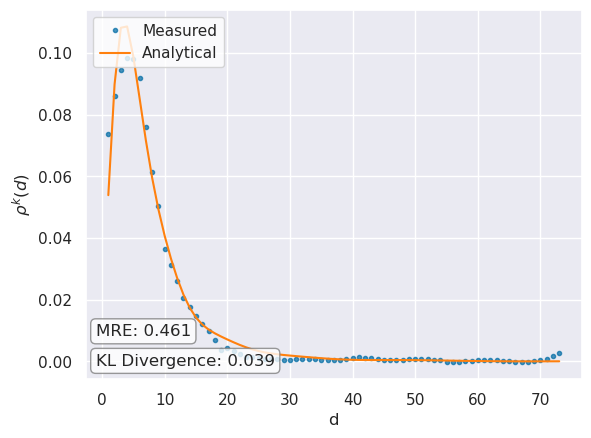

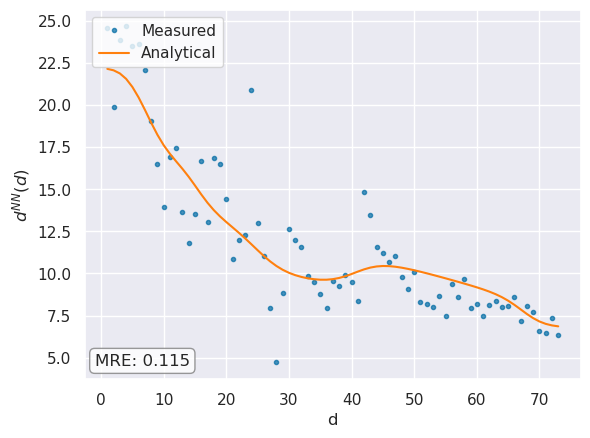

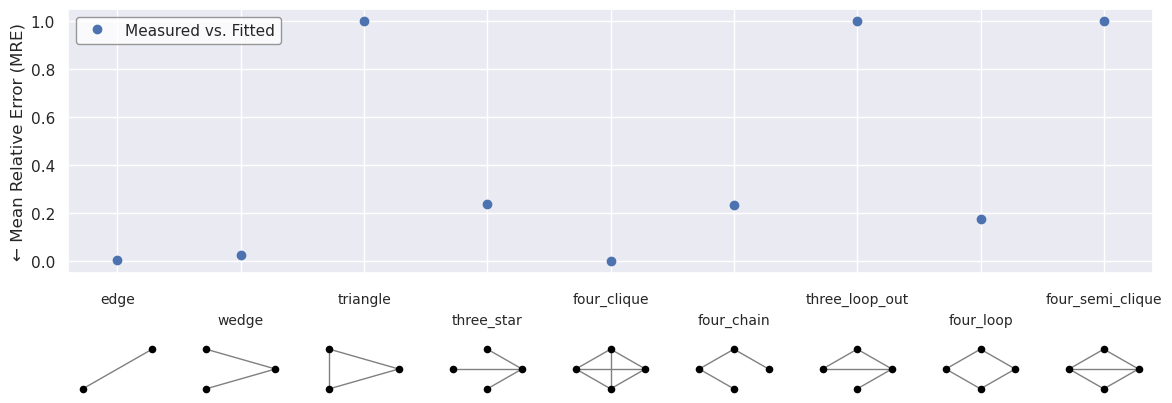

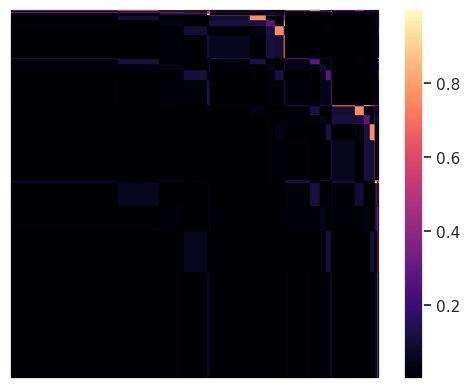

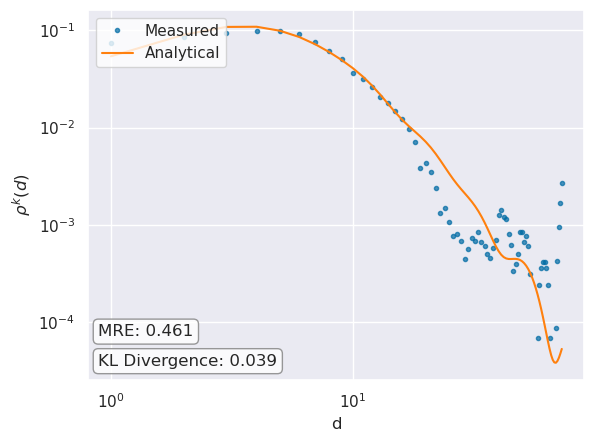

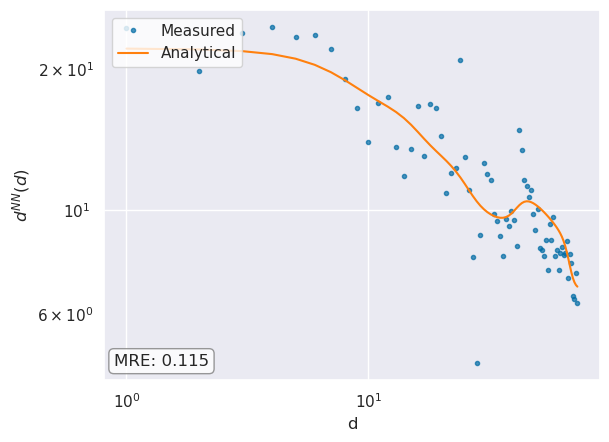

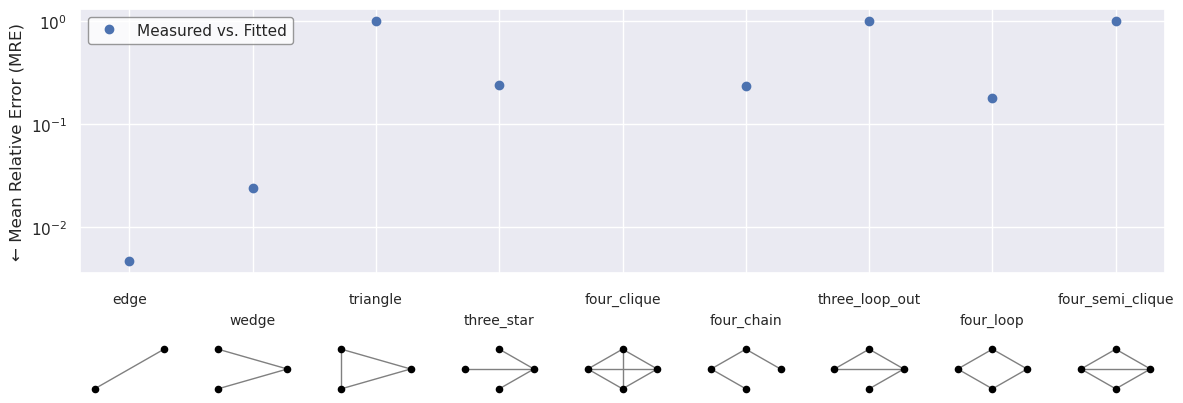

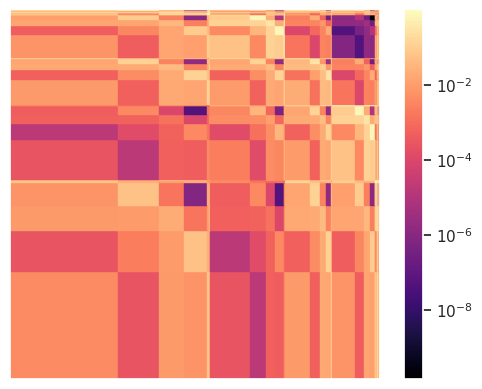

In [11]:
#mfnf.find_P_l(m=11, k=1, one_shot=True)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/celegans_neural_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #xlim=,
    #ylim=,
    #filename = "figures/celegans_neural_log_plot.pdf"
)

# Bootstrapping Stability

In [12]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'median'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [1:05:26<00:00, 130.87s/it]

Bootstrapping: Resampling 200 times...


Bootstrapping finished in 0:00:00.373576
Energy = 9.07 (7.97, 9.47)
l = [0.49 (0.32, 0.83), 0.28 (0.07, 0.38), 0.17 (0.02, 0.28), 0.02 (0.00, 0.15), 0.01 (0.00, 0.04), 0.00 (0.00, 0.02)]
P = [
[0.04 (0.00, 0.23), 0.05 (0.00, 0.33), 0.08 (0.00, 0.49), 0.36 (0.00, 1.00), 0.35 (0.00, 1.00), 0.57 (0.00, 1.00)],

[0.05 (0.00, 0.33), 0.05 (0.00, 0.53), 0.07 (0.00, 0.89), 0.14 (0.00, 0.97), 0.39 (0.00, 1.00), 0.34 (0.00, 0.95)],

[0.08 (0.00, 0.49), 0.07 (0.00, 0.89), 0.12 (0.00, 0.75), 0.15 (0.00, 0.88), 0.15 (0.00, 0.98), 0.36 (0.00, 0.95)],

[0.36 (0.00, 1.00), 0.14 (0.00, 0.97), 0.15 (0.00, 0.88), 0.30 (0.00, 1.00), 0.28 (0.01, 0.95), 0.33 (0.01, 0.94)],

[0.35 (0.00, 1.00), 0.39 (0.00, 1.00), 0.15 (0.00, 0.98), 0.28 (0.01, 0.95), 0.35 (0.00, 1.00), 0.37 (0.00, 0.98)],

[0.57 (0.00, 1.00), 0.34 (0.00, 0.95), 0.36 (0.00, 0.95), 0.33 (0.01, 0.94), 0.37 (0.00, 0.98), 0.32 (0.01, 0.97)]
]


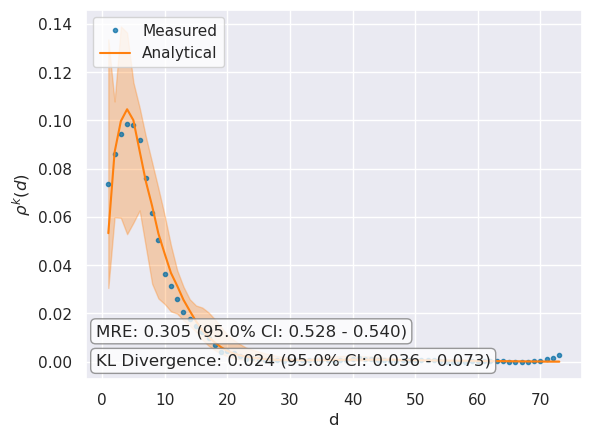

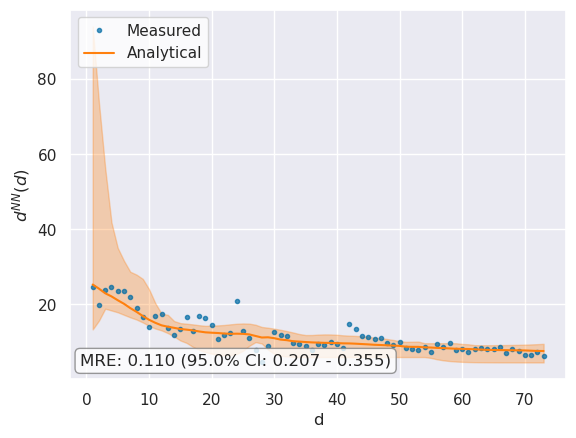

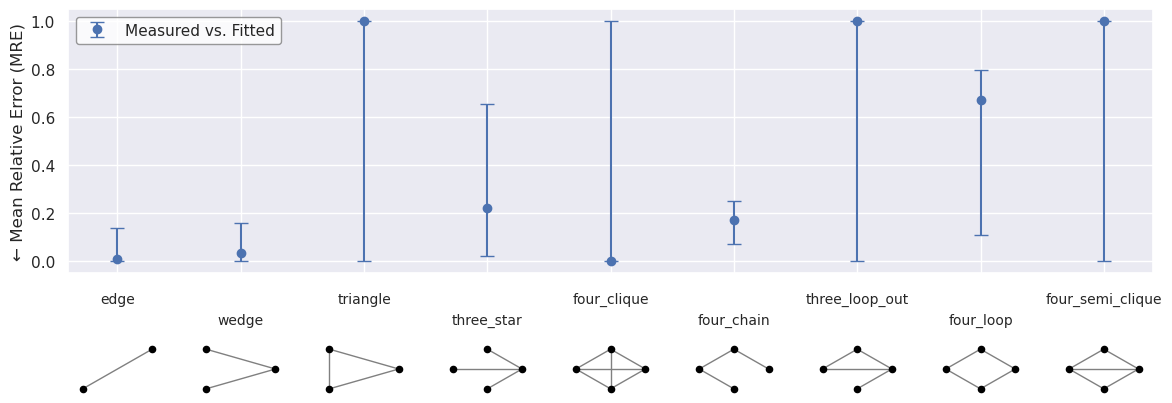

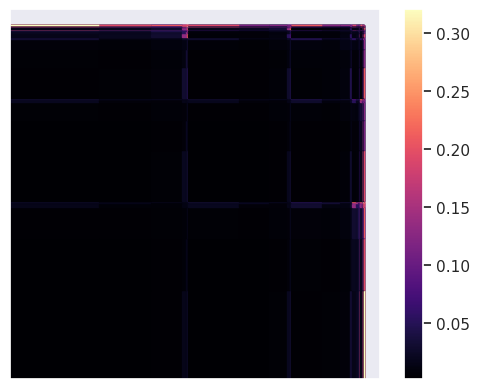

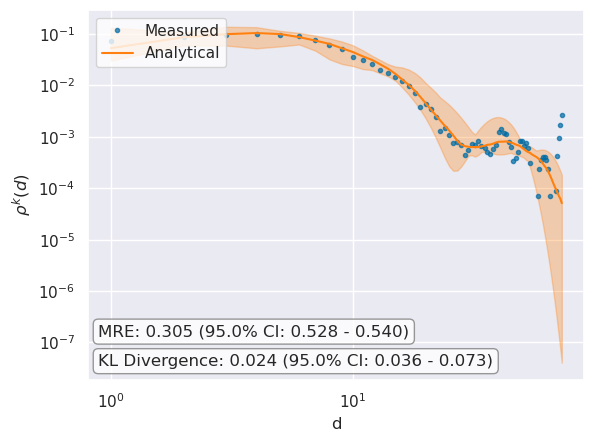

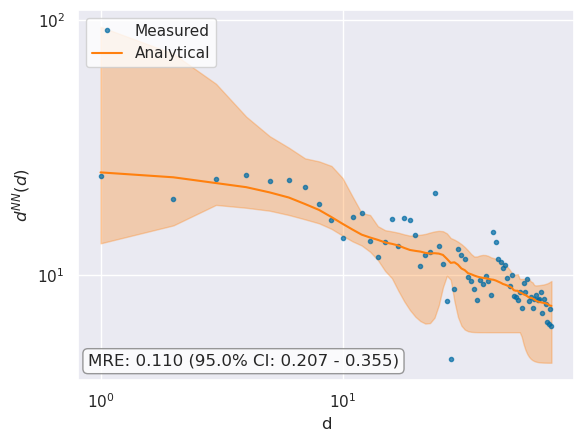

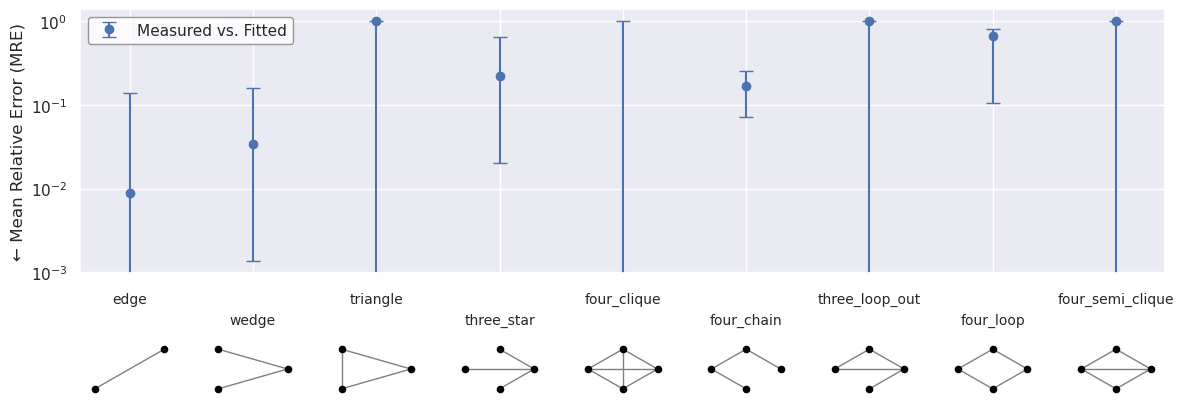

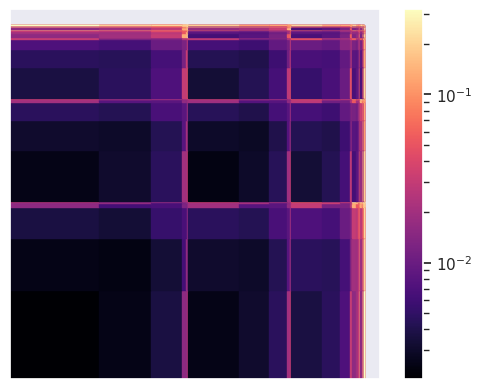

In [13]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/celegans_neural_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #xlim=,
    #ylim=,
    filename = "figures/celegans_neural_log_plot.pdf"
)

In [4]:
import pickle
with open('./test_networks/celegans_neural_mfnf.pkl', 'rb') as f:
    mfnf_ = pickle.load(f)

In [8]:
mfnf_.ground_truth = False

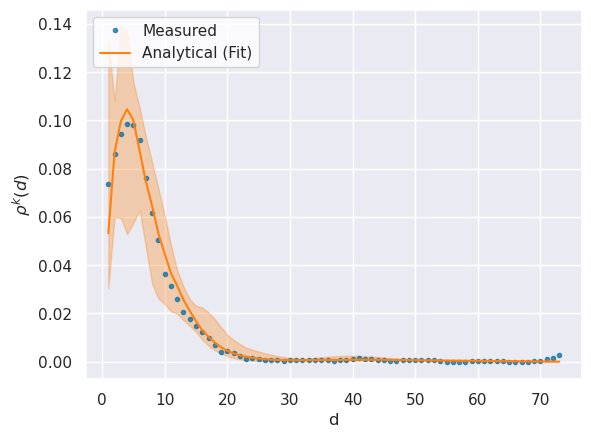

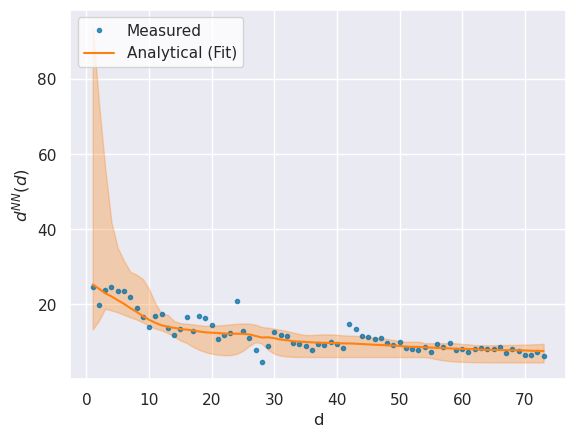

KeyError: 'expected_count'

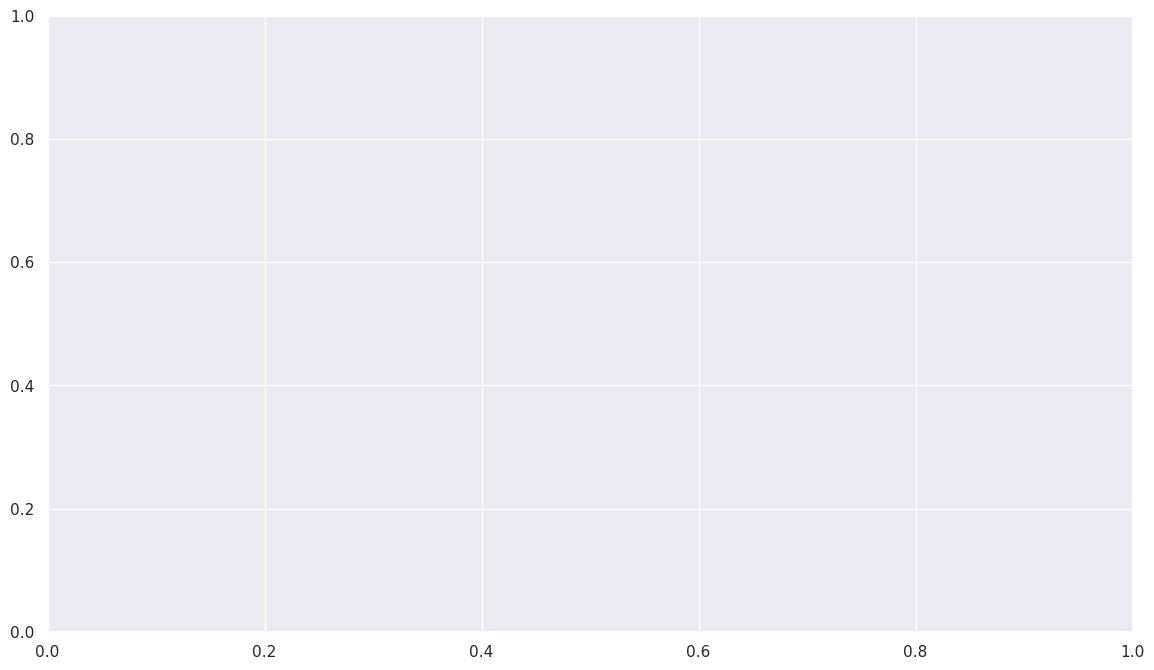

In [11]:
mfnf_.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = False,
    display_kld = False,
    plot_cumulative_error = False,
    #xlim=,
    #ylim=,
    #filename = "figures/celegans_neural_log_plot.pdf"
)

# Generate Variants

Initializing...
0.0005633831024169922
Calculating betweenness...
Done.
Calculating node positions...
Done.


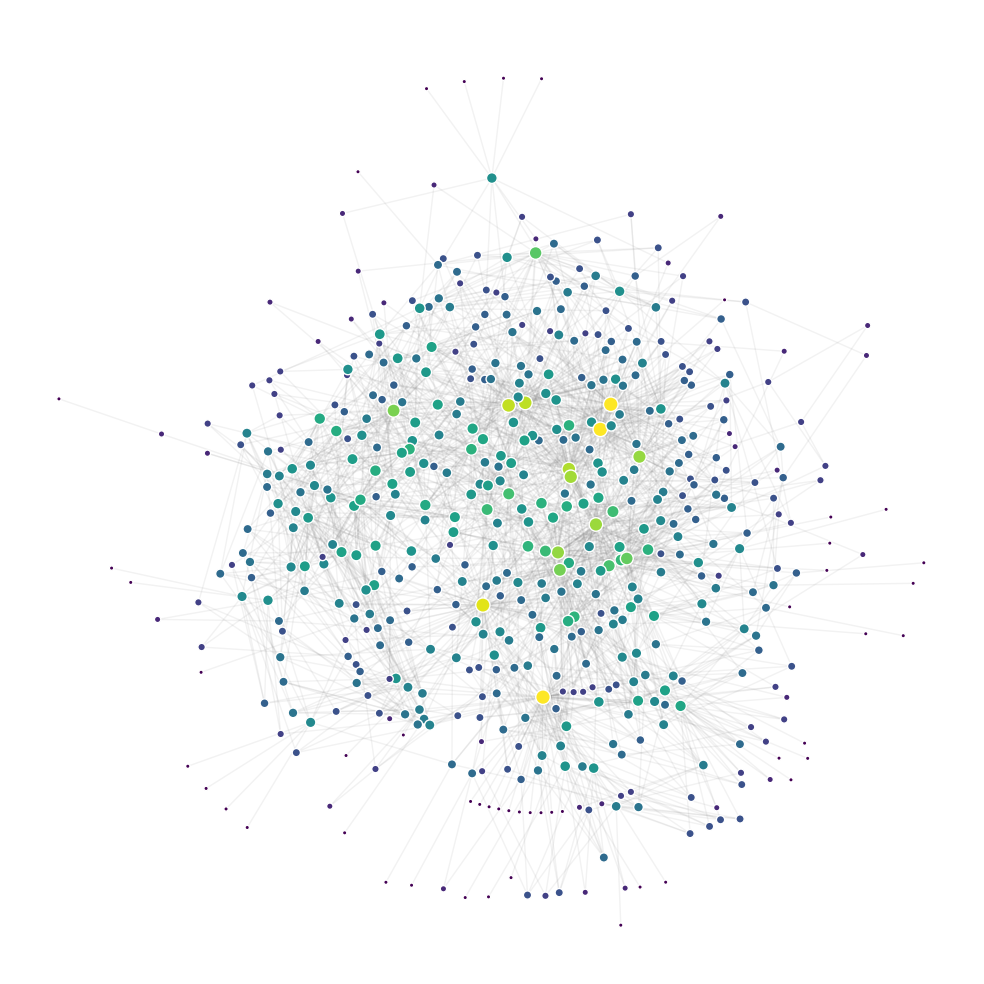

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 371.11it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


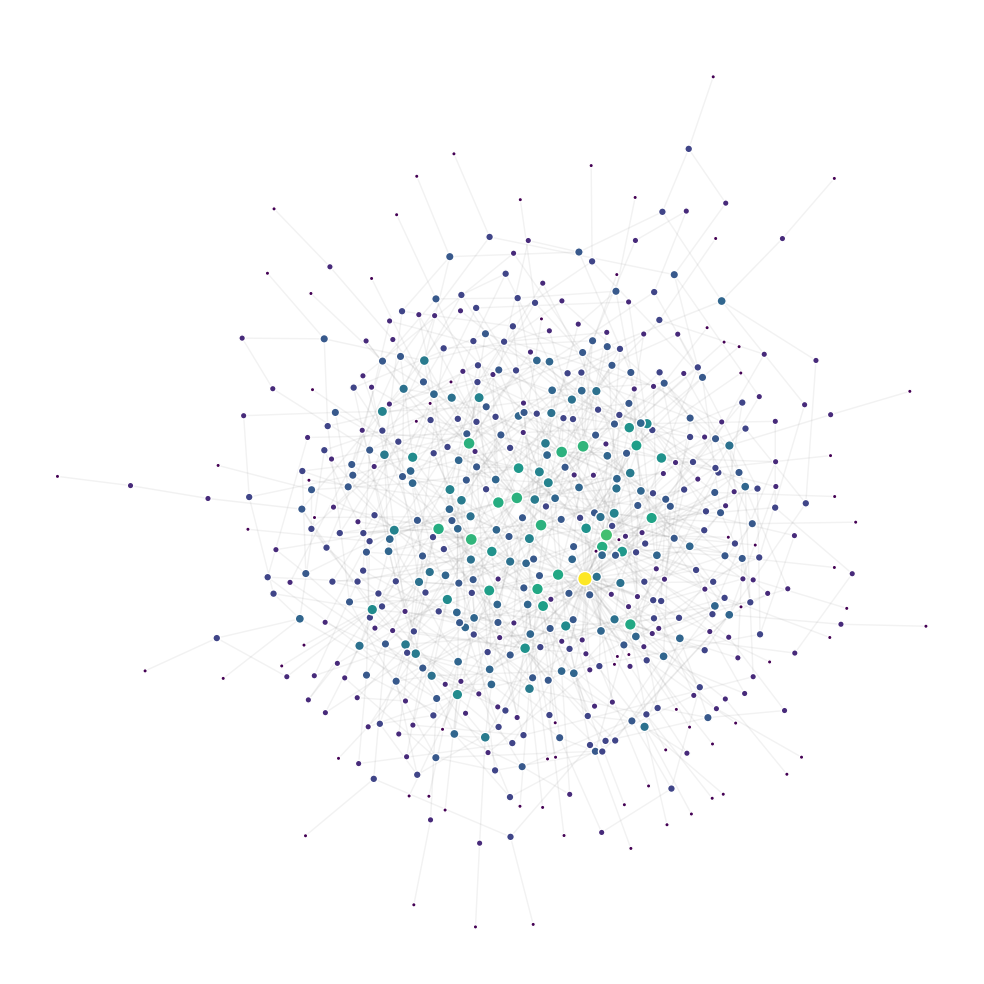

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 367.42it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


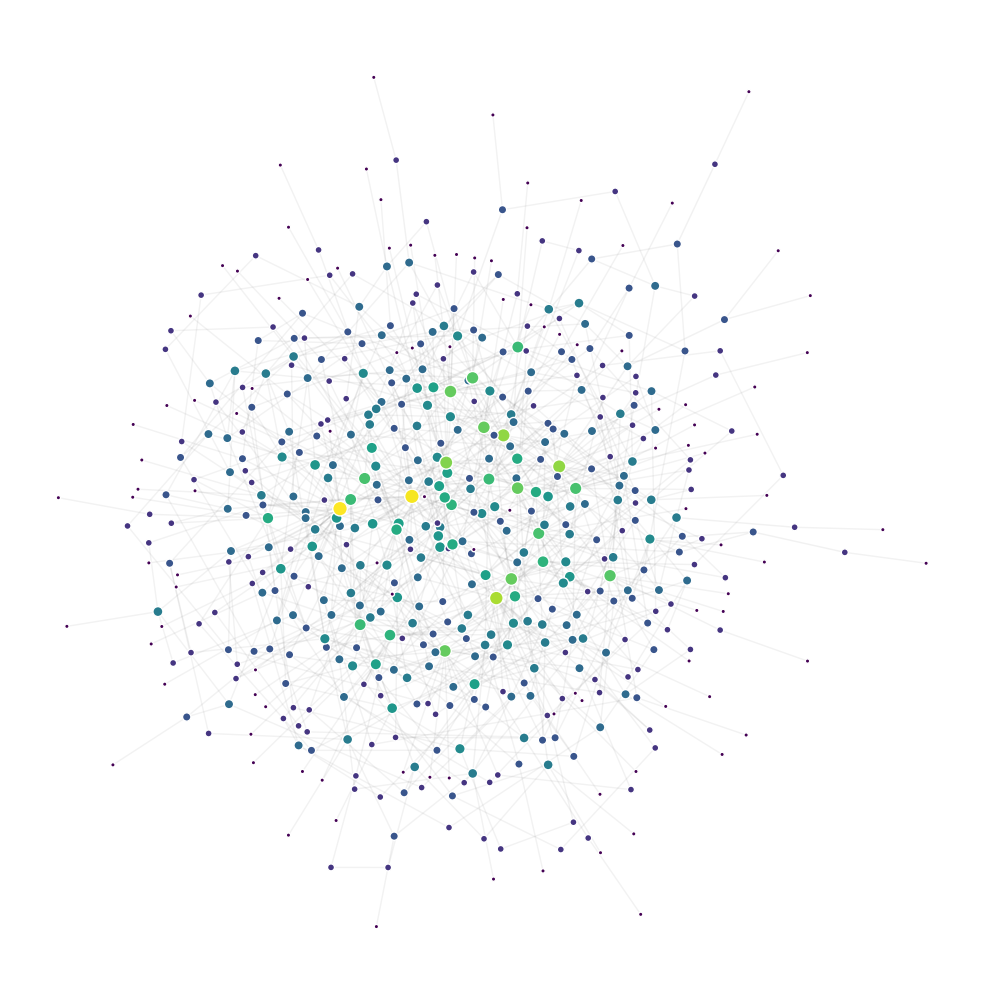

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 350.34it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


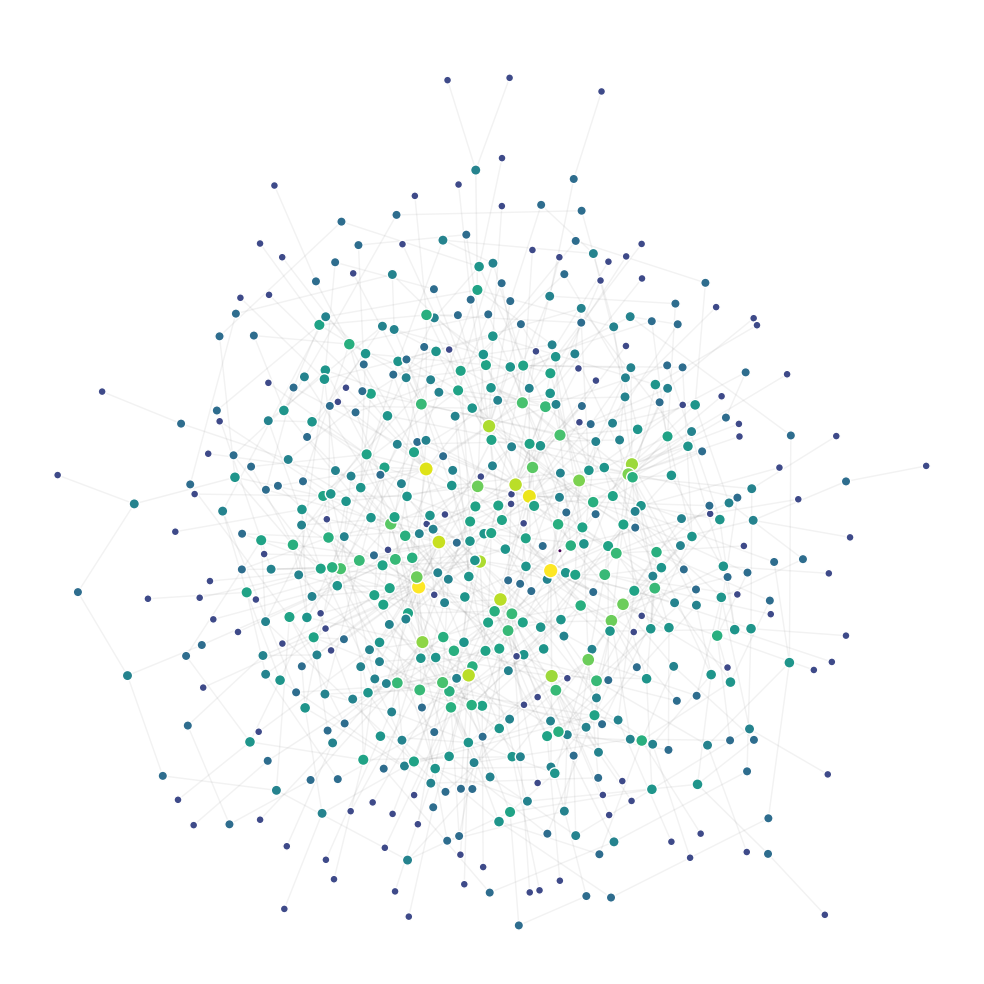

In [14]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.kamada_kawai_layout,
        'figsize': (10,10),
        'filename':  "figures/celegans_neural_variants.pdf"
    },
    filename = "variant_networks/celegans_neural_variants.graphml"
)

In [15]:
import pickle
with open('./test_networks/celegans_neural_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

In [31]:
import pickle
with open('./test_networks/celegans_neural_mfnf.pkl', 'rb') as f:
    mfnf_ = pickle.load(f)

In [32]:
mfnf_.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 2148,
  'MRE': 0.008845437616387336,
  'MRE_ci_low': 0.0,
  'MRE_ci_high': 0.1373370577281192},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 34419,
  'MRE': 0.03379838868146984,
  'MRE_ci_low': 0.0013655248554577414,
  'MRE_ci_high': 0.15767705937056434},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 0,
  'MRE': 1.0,
  'MRE_ci_low': 0.0,
  'MRE_ci_high': 1.0},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 400490,
  'MRE': 0.22170269660999822,
  'MRE_ci_low': 0.020030525106744246,
  'MRE_ci_high': 0.6522667046389908},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,

# Comparison with Benson et. al's Method

In [9]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_star', 'matrix': np.array([[0, 1, 1, 1, 1],[1, 0, 0, 0, 0],[1, 0, 0, 0, 0],[1, 0, 0, 0, 0],[1, 0, 0, 0, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001,
        5: 0.000001,
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 6000,
    weights = {
        'rho':0,
        'deg_nn':0,
        'motifs':1
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 1 user-provided motifs.
Adding custom motif 'four_star'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.074484
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:01.711450
Counting motifs of size 5... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:43.923102


In [10]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 2148},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 34419},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 0},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 400490},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 0},
 {'name': 'four_star',
  'matrix': array([[0, 1, 1, 1, 1],
         [1, 0, 0, 0, 0],
         [1, 0, 0, 0, 0],
         [1, 0, 0, 0, 0],
         [1, 0, 0, 0, 0]]),
  'size': 5,
  'count': 5167733}]

In [11]:
k2 = np.log(len(G))/np.log(2)
print(k2)
k3 = np.log(len(G))/np.log(3)
print(k3)

9.084808387804362
5.731875917361315


In [12]:
mfnf.find_P_l(2,9,one_shot = True)
P2 = mfnf.P
L2 = mfnf.l

Energy: 2.0761156039418784
KL-divergence: 0.05274399528100366
KLD augumented energy: 2.0761156039418784


In [13]:
mfnf.find_P_l(3,5,one_shot = True)
P3 = mfnf.P
L3 = mfnf.l

Energy: 2.0598900626430643
KL-divergence: 0.06636879999670517
KLD augumented energy: 2.0598900626430643


In [15]:
mfnf_no_fit = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9,
        'triangle':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.072544
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:01.679279


In [16]:
mfnf_no_fit.P = P2
mfnf_no_fit.l = L2
mfnf_no_fit.k = 9
mfnf_no_fit._calculate_metrics()
mfnf_no_fit.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 2148,
  'expected_count': 2151,
  'MRE': 0.001394700139470014},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 34419,
  'expected_count': 36157,
  'MRE': 0.04806814724672954},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 0,
  'expected_count': 118,
  'MRE': 1.0},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 400490,
  'expected_count': 389817,
  'MRE': 0.026649853928937053},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 0,
  'expected_count': 0,
  'MRE': 1.0},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 

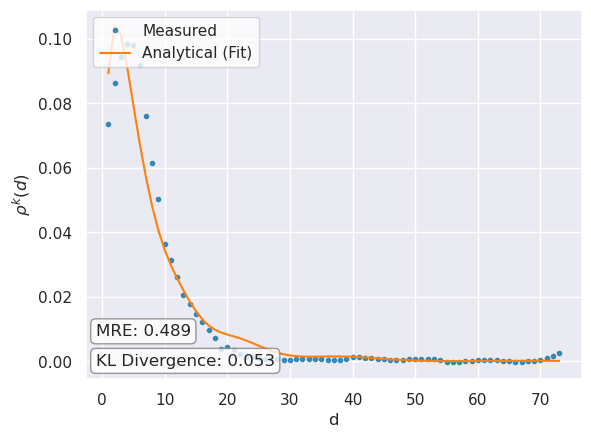

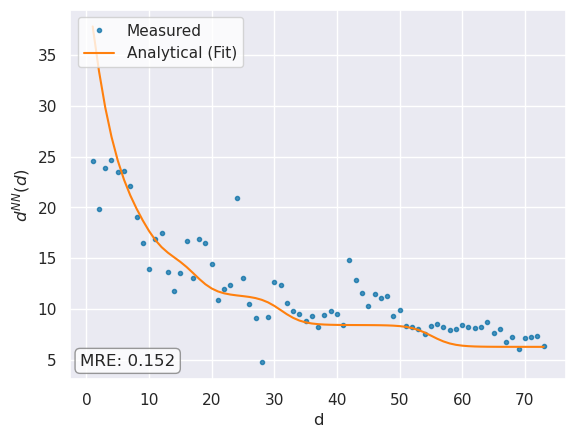

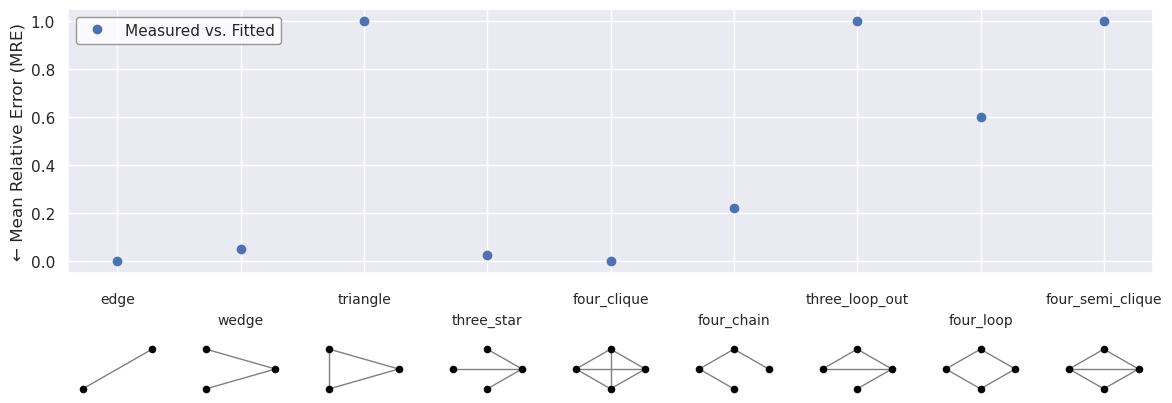

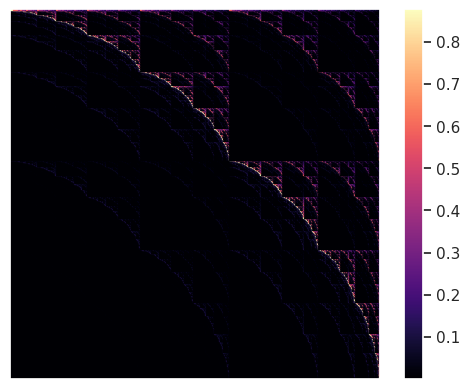

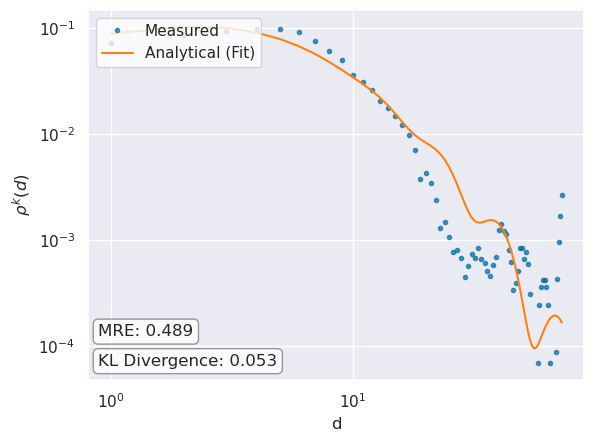

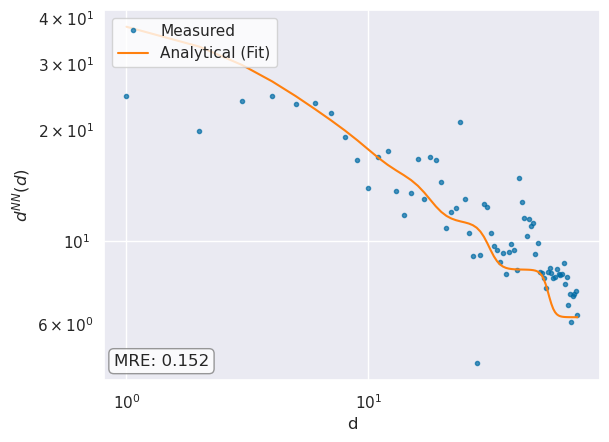

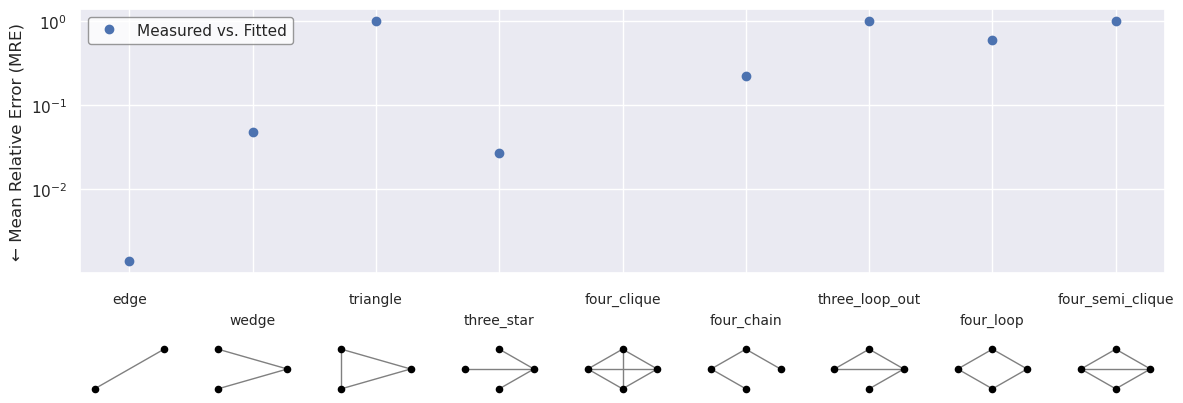

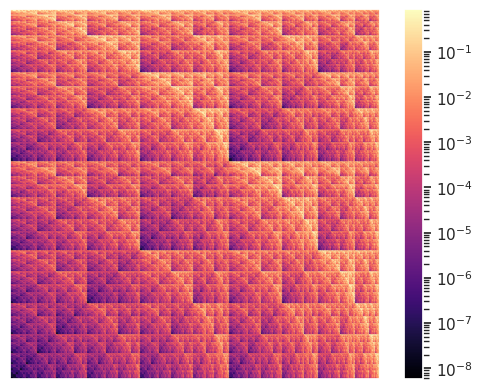

In [17]:
mfnf_no_fit.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/celegans_neural_benson_2_plot.pdf"
)
mfnf_no_fit.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/celegans_neural_benson_2_log_plot.pdf"
)

In [18]:
mfnf_no_fit.P = P3
mfnf_no_fit.l = L3
mfnf_no_fit.k = 5
mfnf_no_fit._calculate_metrics()
mfnf_no_fit.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 2148,
  'expected_count': 2148,
  'MRE': 0.0},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 34419,
  'expected_count': 35961,
  'MRE': 0.04287978643530491},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 0,
  'expected_count': 101,
  'MRE': 1.0},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 400490,
  'expected_count': 393875,
  'MRE': 0.016517266348722814},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 0,
  'expected_count': 0,
  'MRE': 1.0},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
       

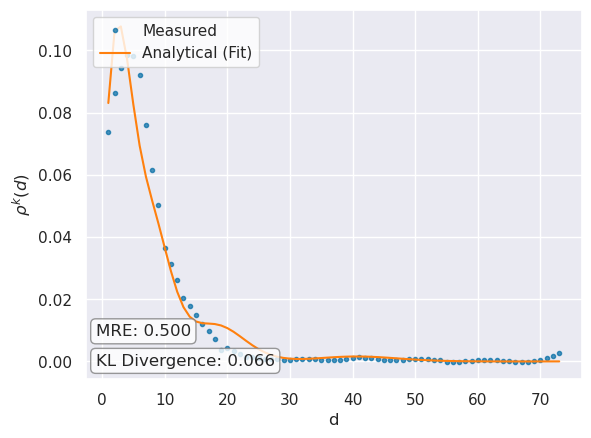

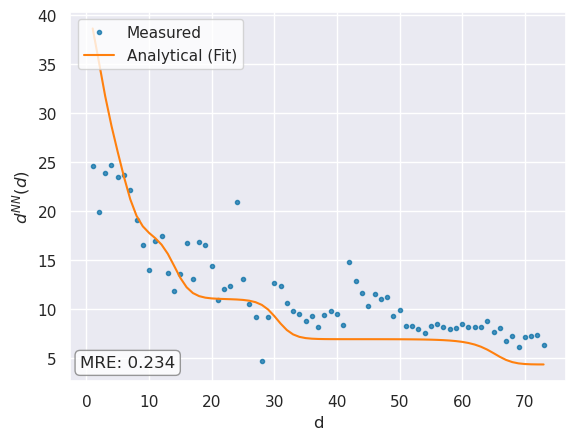

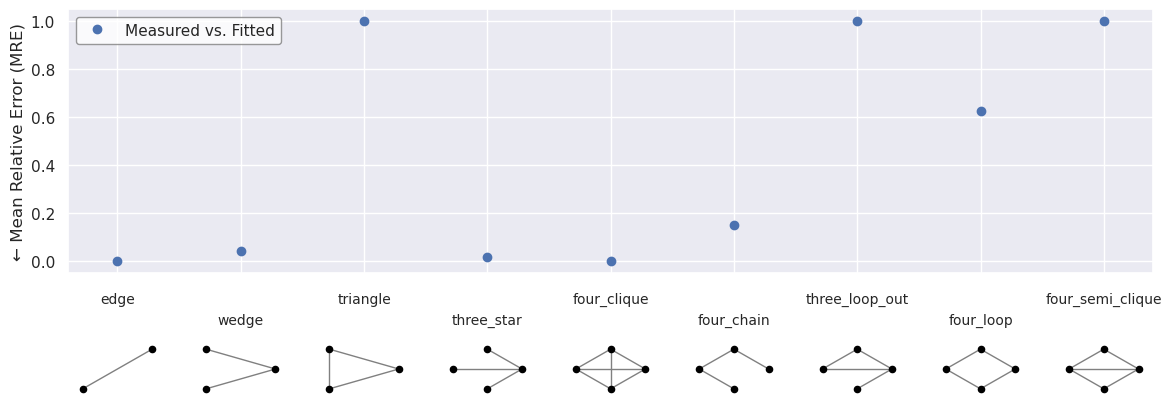

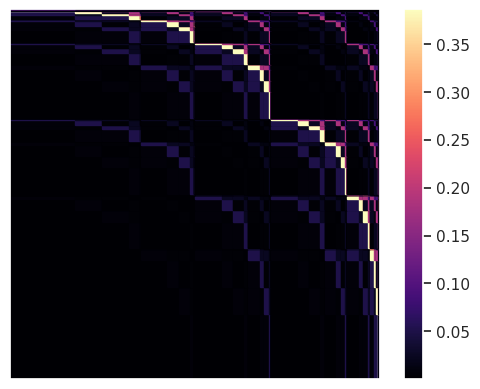

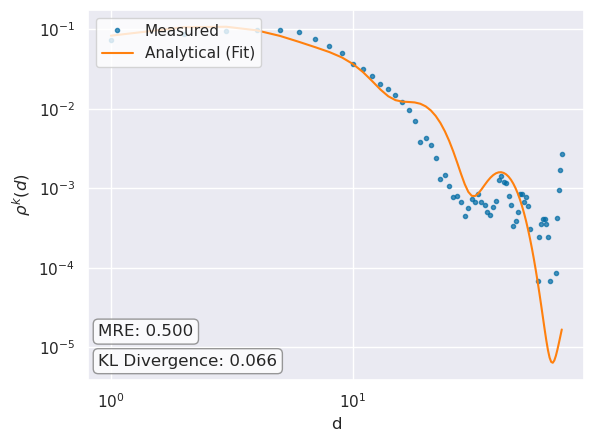

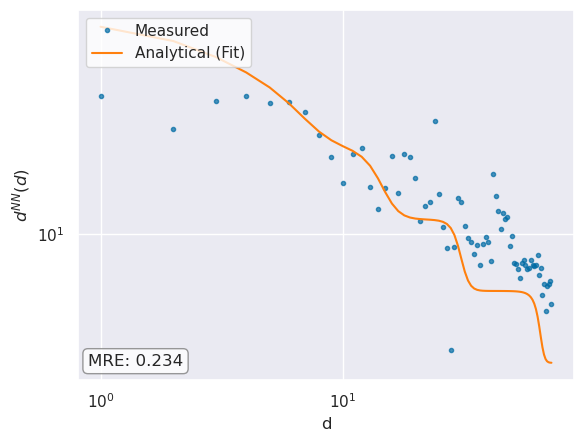

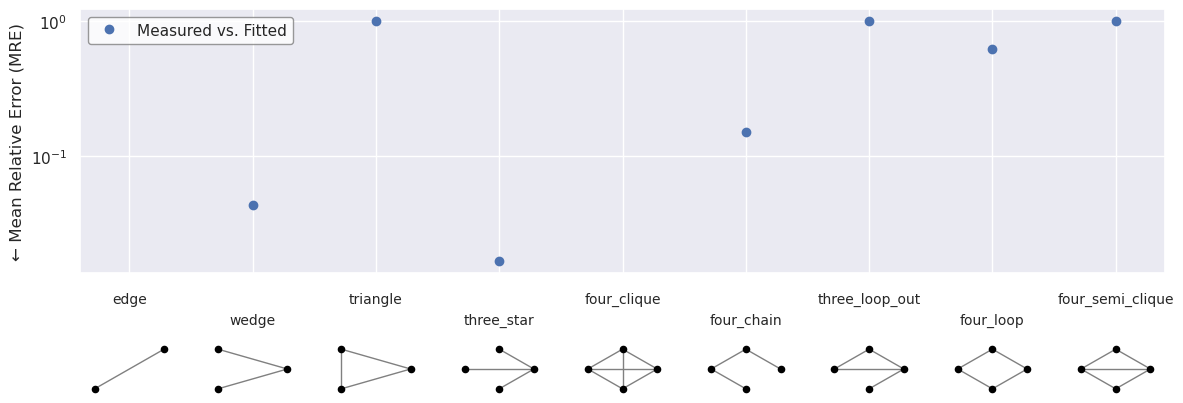

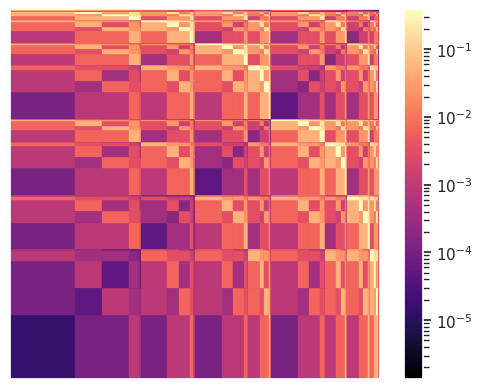

In [19]:
mfnf_no_fit.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/celegans_neural_benson_3_plot.pdf"
)
mfnf_no_fit.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/celegans_neural_benson_3_log_plot.pdf"
)